**Import Libraries**

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from datetime import datetime

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

print('Successfully imported modules...')

Successfully imported modules...


**Initial Look on the Data**

In [3]:
# create dataframe

file_path = r'/content/social-media-sentiments-analysis/dataset/sentimentdataset.csv'

df = pd.read_csv(file_path)

print('Successfully created dataframe...')

Successfully created dataframe...


In [91]:
# df metadata

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [92]:
# first fop rows
print('Top 5 Rows: ')
display(df.head())
print('\nLast 5 Rows:')
display(df.tail())

Top 5 Rows: 


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park!,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway!,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight.,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19



Last 5 Rows:


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
727,728,732,Collaborating on a science project that received recognition at a regional fair. Science triumphs and smiles!,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20.0,39.0,UK,2017,8,18,18
728,729,733,"Attending a surprise birthday party organized by friends. Surrounded by love, laughter, and good company!",Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25.0,48.0,USA,2018,6,22,14
729,730,734,Successfully fundraising for a school charity initiative. The joy of giving back to the community!,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22.0,42.0,Canada,2019,4,5,17
730,731,735,"Participating in a multicultural festival, celebrating diversity with music, dance, and delicious food!",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21.0,43.0,UK,2020,2,29,20
731,732,736,"Organizing a virtual talent show during challenging times, bringing smiles to classmates' faces!",Happy,2020-11-15 15:15:00,VirtualTalentShowSuccessHighSchool,Instagram,#VirtualEntertainment #HighSchoolPositivity,24.0,47.0,USA,2020,11,15,15


In [93]:
# return each number of unique values per column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0.1,732
Unnamed: 0,732
Text,707
Hashtags,697
User,685
Timestamp,683
Sentiment,279
Country,115
Likes,38
Day,31


In [94]:
# descriptive statisticsfor num cols
df.describe().round(2).map(lambda x: f'{x:g}')

,Unnamed: 0.1,Unnamed: 0,Retweets,Likes,Year,Month,Day,Hour
count,732,732,732,732,732,732,732,732
mean,366.46,369.74,21.51,42.9,2020.47,6.12,15.5,15.52
std,211.51,212.43,7.06,14.09,2.8,3.41,8.47,4.11
min,0,0,5,10,2010,1,1,0
25%,183.75,185.75,17.75,34.75,2019,3,9,13
50%,366.5,370.5,22,43,2021,6,15,16
75%,549.25,553.25,25,50,2023,9,22,19
max,732,736,40,80,2023,12,31,23


In [95]:
# descriptive statistics for cat cols
df.describe(include='O').T

,count,unique,top,freq
Text,732,707,"A compassionate rain, tears of empathy falling gently, nurturing the seeds of kindness in the garden of human connections.",3
Sentiment,732,279,Positive,44
Timestamp,732,683,2019-04-05 17:30:00,3
User,732,685,WinterWarmth,3
Platform,732,4,Instagram,258
Hashtags,732,697,#Hopeful #SeedsOfOptimism,3
Country,732,115,USA,59


**Data Quality**

In [4]:
# to prevent alteration
data = df.copy()

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB
None


In [98]:
# drop columns
data = data.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'], errors='ignore')

row, col = data.shape
print(f'Total Number of Rows: {row}')
print(f'Total Number of Columns: {col}\n')
print('Successfully dropped columns...')

Total Number of Rows: 711
Total Number of Columns: 14

Successfully dropped columns...


In [24]:
# inspect data types
df.dtypes

,0
Unnamed: 0.1,int64
Unnamed: 0,int64
Text,object
Sentiment,object
Timestamp,object
User,object
Platform,object
Hashtags,object
Retweets,float64
Likes,float64


In [99]:
# convert timestamp to datetime
data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# inspect conversion
data['Timestamp'].dtype

dtype('<M8[ns]')

In [26]:
# address inconsistencies
cols = data[['Sentiment', 'Country', 'Platform', 'User']]

for col in cols:
  data[col] = data[col].str.strip()

  print(f'{col}:')
  print(data[col].value_counts(dropna=False).to_string(header=False))
  print("=====" * 10)

Sentiment:
Positive                45
Joy                     44
Excitement              37
Contentment             18
Neutral                 18
Gratitude               17
Curiosity               16
Serenity                15
Happy                   14
Despair                 11
Nostalgia               11
Awe                      9
Grief                    9
Sad                      9
Acceptance               8
Loneliness               8
Embarrassed              8
Confusion                8
Determination            7
Euphoria                 7
Enthusiasm               7
Pride                    7
Elation                  7
Ambivalence              6
Hopeful                  6
Frustration              6
Numbness                 6
Surprise                 6
Melancholy               6
Regret                   6
Indifference             6
Inspiration              6
Hate                     6
Bad                      6
Frustrated               5
Hope                     5
Empowerment      

In [27]:
# check if df has duplicates
has_duplicates = data.duplicated().any()
print(f'Are there duplicates in the dataset?: {has_duplicates}')

duplicate_count = data.duplicated().sum()
print(f'Number of duplicates: {duplicate_count}')

Are there duplicates in the dataset?: True
Number of duplicates: 1


In [28]:
data[data.duplicated(subset=['Text'], keep=False)]

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
264,"A compassionate rain, tears of empathy falling gently, nurturing the seeds of kindness in the garden of human connections.",Compassionate,2021-07-01 12:10:00,RainNurturer,Facebook,#Compassionate #TearsOfEmpathy,21.0,42.0,Canada,2021,7,1,12
266,"Embraced by the hopeful dawn, a gardener sowing seeds of optimism, tending to the blooms of a brighter tomorrow.",Hopeful,2022-07-17 06:15:00,DawnGardener,Instagram,#Hopeful #SeedsOfOptimism,14.0,28.0,UK,2022,7,17,6
278,"A compassionate rain, tears of empathy falling gently, nurturing the seeds of kindness in the garden of human connections.",Compassionate,2021-07-01 12:10:00,RainNurturer,Instagram,#Compassionate #TearsOfEmpathy,21.0,42.0,Canada,2021,7,1,12
294,"Embraced by the hopeful dawn, a gardener sowing seeds of optimism, tending to the blooms of a brighter tomorrow.",Hopeful,2022-07-17 06:15:00,DawnGardener,Instagram,#Hopeful #SeedsOfOptimism,14.0,28.0,India,2022,7,17,6
308,"Shattered dreams lie on the floor like fragments of glass, a mosaic of disappointment crafted by the hands of frustration.",Frustrated,2022-01-07 11:10:00,DreamMosaic,Instagram,#Frustrated #MosaicOfDisappointment,15.0,30.0,Canada,2022,1,7,11
317,"Dismissive gestures, a curtain drawn to shield the vulnerability, a stage where emotions take a backseat to the performance of indifference.",Dismissive,2018-08-18 14:40:00,CurtainShield,Instagram,#Dismissive #IndifferencePerformance,12.0,24.0,Australia,2018,8,18,14
329,"Dismissive gestures, a curtain drawn to shield the vulnerability, a stage where emotions take a backseat to the performance of indifference.",Dismissive,2018-08-18 14:00:00,IndifferentFort,Instagram,#Dismissive #IndifferencePerformance,12.0,24.0,Australia,2018,8,18,14
330,"Shattered dreams lie on the floor like fragments of glass, a mosaic of disappointment crafted by the hands of frustration.",Frustrated,2022-01-07 11:10:00,DreamMosaic,Twitter,#Frustrated #MosaicOfDisappointment,15.0,30.0,Canada,2022,1,7,11
384,Whispers of inspiration from the rustling leaves in a serene forest.,Inspiration,2016-11-15 11:45:00,ForestDreamer,Facebook,#Inspiration #ForestWhispers,28.0,55.0,Portugal,2016,11,15,11
404,Whispers of inspiration from the rustling leaves in a serene forest.,Inspiration,2016-11-15 11:45:00,ForestDreamer,Facebook,#Inspiration #ForestWhispers,28.0,55.0,Portugal,2016,11,15,11


In [29]:
# drop duplicates
data = data.drop_duplicates()

print("You have successfully dropped duplicates in the dataset...\n")
print('Count of rows after removing duplicates', len(data))
print('Count of duplicates in the dataset:', data.duplicated().sum())

You have successfully dropped duplicates in the dataset...

Count of rows after removing duplicates 711
Count of duplicates in the dataset: 0


In [30]:
# Check for missing values
any_missing = data.isnull().any().sort_values(ascending=False)
print("Missing value status per column:")
print(any_missing)

missing_count = data.isnull().sum().sort_values(ascending=False)
print("\nMissing value count per column:")
print(missing_count)

Missing value status per column:
Text         False
Sentiment    False
Timestamp    False
User         False
Platform     False
Hashtags     False
Retweets     False
Likes        False
Country      False
Year         False
Month        False
Day          False
Hour         False
dtype: bool

Missing value count per column:
Text         0
Sentiment    0
Timestamp    0
User         0
Platform     0
Hashtags     0
Retweets     0
Likes        0
Country      0
Year         0
Month        0
Day          0
Hour         0
dtype: int64


## **Exploratory Data Analysis**

### **Engagement Metrics Analysis and Outlier Investigation**

**Observations:**

- The average engagement per post is 64.48, with a standard deviation of 21.34, indicating some variation in engagement levels.
- The median engagement is 65, meaning approximately half of the posts have 65 or fewer interactions, while the other half have 65 or more.
- The middle 50% of posts have total engagement values ranging from 52 to 75.
- Total engagement ranges from 15 to 120 interactions, showing a difference of 105 between the lowest and highest recorded values.
- The distribution appears relatively symmetrical, as the mean (64.48) and median (65) are close to each other. This observation can be further assessed using the histogram.

In [31]:
# inspect numerical cols
data[['Retweets', 'Likes']].describe().round(2).map(lambda x: f'{x:g}').T

,count,mean,std,min,25%,50%,75%,max
Retweets,711,21.53,7.13,5,17.5,22,25,40
Likes,711,42.95,14.22,10,34.5,43,50,80


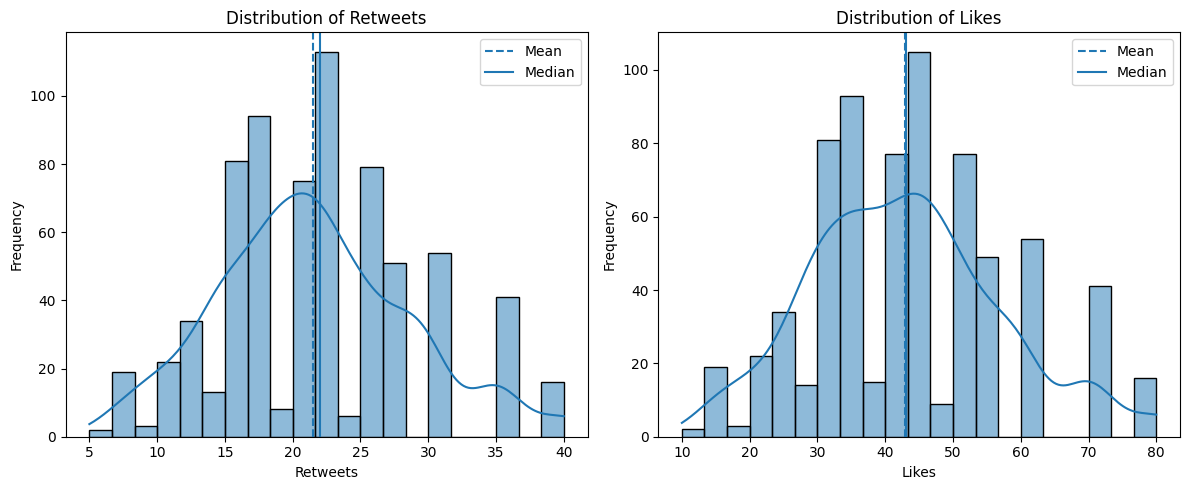

In [32]:
# Plot histograms
num_cols = data[['Retweets', 'Likes']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, num_cols):

    sns.histplot(data=data, x=col, kde=True, ax=ax)

    ax.axvline(data[col].mean(), linestyle='--', label='Mean')
    ax.axvline(data[col].median(), linestyle='-', label='Median')

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.show()

In [33]:
# inspect for outliers
def main():

  identify_outliers()

def identify_outliers():

  q1 = num_cols.quantile(0.25)
  q3 = num_cols.quantile(0.75)

  iqr = q3 - q1

  lower_limit = q1 - 1.5 * iqr
  upper_limit = q3 + 1.5 * iqr

  for col in num_cols:

    lower_outliers = num_cols[col][num_cols[col] < lower_limit[col]]
    upper_outliers = num_cols[col][num_cols[col] > upper_limit[col]]


    print(f'{col}:')

    print(f'Number of Lower Outliers: {len(lower_outliers)}')
    print(f'Lower Limit: {lower_limit[col]}')
    print(f'Lower Outliers: {lower_outliers.tolist()}')


    print(f'Number of Upper Outliers: {len(upper_outliers)}')
    print(f'Upper Limit: {upper_limit[col]}')
    print(f'Upper Outliers: {upper_outliers.tolist()}')


    print("=====" * 25)

main()

Retweets:
Number of Lower Outliers: 2
Lower Limit: 6.25
Lower Outliers: [5.0, 5.0]
Number of Upper Outliers: 16
Upper Limit: 36.25
Upper Outliers: [40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0]
Likes:
Number of Lower Outliers: 2
Lower Limit: 11.25
Lower Outliers: [10.0, 10.0]
Number of Upper Outliers: 16
Upper Limit: 73.25
Upper Outliers: [80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0]


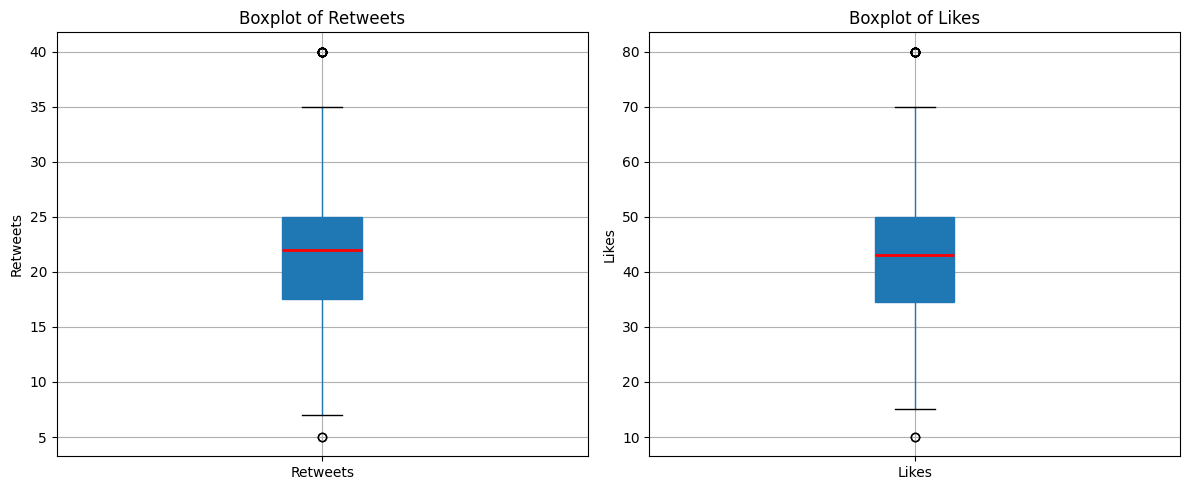

In [42]:
# plot boxplot

fig, axes = plt.subplots(1, 2, figsize=(12,5))

for ax, col in zip(axes, num_cols):

  data.boxplot(
               column=[col],
               ax=ax,
               patch_artist=True,
               medianprops={
                   'color': 'red',
                   'linewidth': 2
                   }
               )

  ax.set_title(f'Boxplot of {col}')
  ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [43]:
# create a new column combining likes and retweets
data['Total Engagement'] = data['Likes'] + data['Retweets']

# inspect new column
data.head()

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour,Total Engagement
0,Enjoying a beautiful day at the park!,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12,45.0
1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8,15.0
2,Just finished an amazing workout! 💪,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15,60.0
3,Excited about the upcoming weekend getaway!,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18,23.0
4,Trying out a new recipe for dinner tonight.,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19,37.0


In [44]:
# inspect descriptive statistics for the total engagement
data['Total Engagement'].describe().round(2).map(lambda x: f'{x:g}')

,Total Engagement
count,711
mean,64.48
std,21.34
min,15
25%,52
50%,65
75%,75
max,120


In [45]:
data['Total Engagement'].value_counts()

,count
Total Engagement,
67.0,95
53.0,76
75.0,72
45.0,72
60.0,61
90.0,54
83.0,49
105.0,41
37.0,23


In [46]:
outliers = data[
    (data['Total Engagement'] < 17.5) |
    (data['Total Engagement'] > 109.5)
]

outliers

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour,Total Engagement
1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8,15.0
163,Suffering from despair after another setback.,Despair,2021-03-10 08:30:00,StrugglingSoul,Twitter,#Despair #Struggle,5.0,10.0,USA,2021,3,10,8,15.0
335,Thrilled to witness the grandeur of a cultural festival.,Thrill,2020-09-15 14:45:00,CultureEnthusiast,Instagram,#Thrill #CulturalCelebration,40.0,80.0,India,2020,9,15,14,120.0
345,Motivated to achieve fitness goals after an invigorating workout.,Motivation,2022-02-28 07:15:00,FitnessJunkie,Facebook,#Motivation #FitnessGoals,40.0,80.0,Australia,2022,2,28,7,120.0
355,Anticipation for an upcoming adventure in an exotic destination.,Anticipation,2022-07-25 10:00:00,Wanderlust,Twitter,#Anticipation #AdventureAwaits,40.0,80.0,India,2022,7,25,10,120.0
368,Elation over discovering a rare book in a quaint bookstore.,Elation,2018-09-22 16:30:00,Bookworm,Instagram,#Elation #RareBookDiscovery,40.0,80.0,USA,2018,9,22,16,120.0
382,A sense of wonder at the vastness of the cosmos on a stargazing night.,Wonder,2018-07-08 23:00:00,CosmosExplorer,Instagram,#Wonder #StargazingAdventure,40.0,80.0,South Africa,2018,7,8,23,120.0
402,Awe-inspired by the vastness of the cosmos on a stargazing night.,Wonder,2018-07-08 23:00:00,CosmosExplorer,Instagram,#Wonder #StargazingAdventure,40.0,80.0,South Africa,2018,7,8,23,120.0
432,"Heartache deepens, a solitary journey through the abyss of despair.",Despair,2022-08-18 22:00:00,SolitaryDescent,Instagram,#Despair #AbyssOfHeartache,40.0,80.0,South Africa,2022,8,18,22,120.0
470,"Dancing on sunshine, each step a celebration of the joy found in simple moments.",Joy,2021-08-20 15:45:00,SunshineDancer,Instagram,#Joy #SimpleMoments,40.0,80.0,USA,2021,8,20,15,120.0


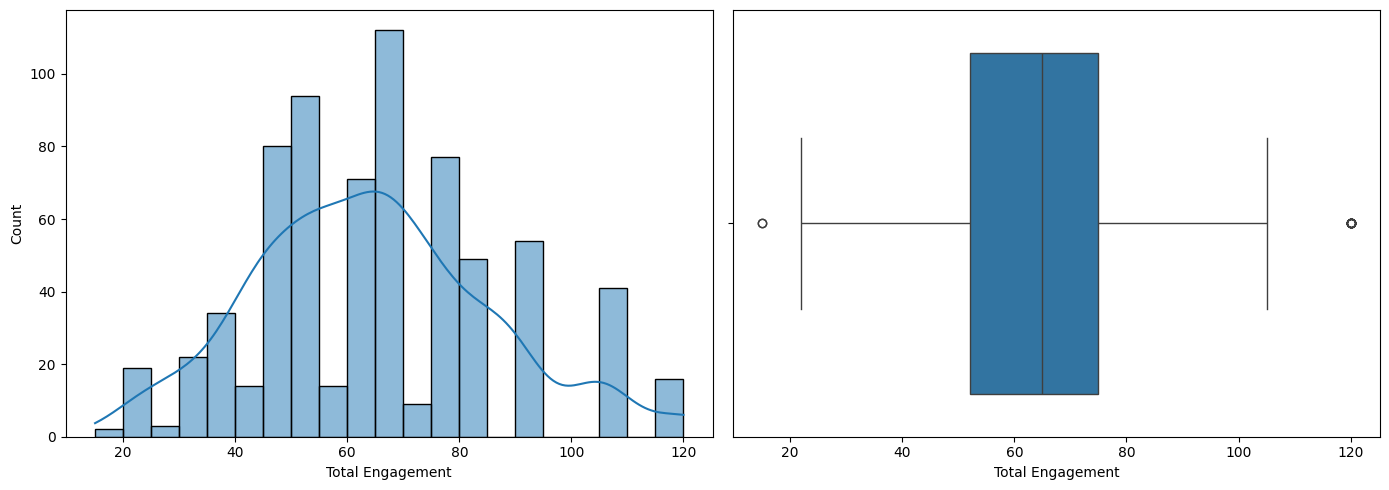

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=data, x='Total Engagement', kde=True, ax=axes[0])
sns.boxplot(data=data, x='Total Engagement', ax=axes[1])

plt.tight_layout()
plt.show()

### **Sentiment Distribution Analysis**

**Observations:**

- The dataset contains 191 unique sentiment labels, some of which have overlapping or semantically similar meanings. These labels were retained in their original form to preserve the dataset's classifications and avoid introducing subjective grouping assumptions.
- Positive is the most frequent sentiment, with 45 posts, closely followed by Joy (44) and Excitement (37).
- Contentment and Neutral are tied at 18 posts each.
- The remaining categories have considerably lower frequencies, with Determination and Euphoria appearing seven times each among the top 20.
- The distribution indicates that sentiment labels are highly fragmented, with many categories appearing only a few times.

In [49]:
sentiment_count = data['Sentiment'].nunique()
print(f'Number of unique values in the Sentiment column: {sentiment_count}')

Number of unique values in the Sentiment column: 191


In [50]:
# check frequency and percentage of each sentiment

sentiment_counts = pd.concat([
    data['Sentiment'].value_counts(),
    data['Sentiment'].value_counts(normalize=True)
], axis=1)

sentiment_counts.columns = ['Frequency', 'Percentage (%)']

sentiment_counts

,Frequency,Percentage (%)
Sentiment,,
Positive,45,0.063291
Joy,44,0.061885
Excitement,37,0.052039
Contentment,18,0.025316
Neutral,18,0.025316
Gratitude,17,0.023910
Curiosity,16,0.022504
Serenity,15,0.021097
Happy,14,0.019691


In [51]:
# check how many sentiment categories have a particular number of posts
sentiment_counts.value_counts()

,,count
Frequency,Percentage (%),
1,0.001406,81
2,0.002813,31
3,0.004219,24
4,0.005626,14
6,0.008439,10
5,0.007032,8
7,0.009845,5
8,0.011252,4
9,0.012658,3


In [52]:
data['Sentiment'].value_counts().head(20)

,count
Sentiment,
Positive,45
Joy,44
Excitement,37
Contentment,18
Neutral,18
Gratitude,17
Curiosity,16
Serenity,15
Happy,14


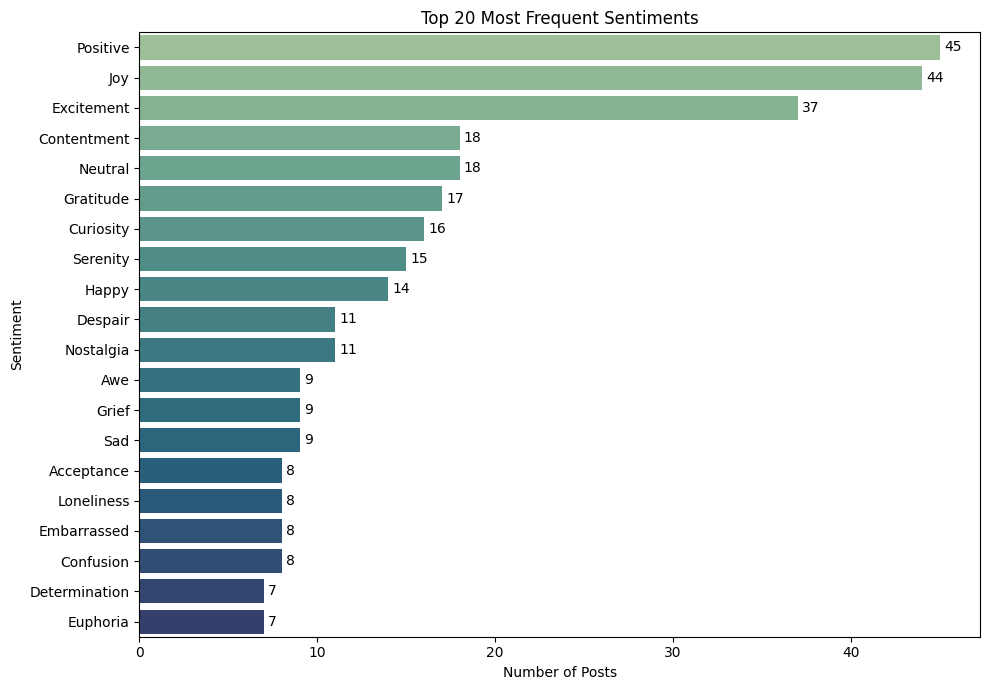

In [53]:
# Get top 20 sentiment categories
top_sentiments = data['Sentiment'].value_counts().head(20)

# Plot horizontal bar chart
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=top_sentiments.values,
    y=top_sentiments.index,
    palette='crest'
)

# add bar labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3
  )

plt.title('Top 20 Most Frequent Sentiments')
plt.xlabel('Number of Posts')
plt.ylabel('Sentiment')

plt.tight_layout()
plt.show()

### **Sentiment Distribution Across Platforms Analysis**

**Observations:**

**Facebook**
- Joy is the most frequent sentiment, with 20 posts, followed by Positive (16) and Excitement (11).
- Contentment, Neutral, Gratitude, and Curiosity each have 6 posts, while Serenity has 5. Happy and Despair each have 4 posts.
- Joy, Positive, and Excitement are the three most frequently occurring sentiment labels on Facebook.

**Instagram**
- Positive is the most frequent sentiment, with 16 posts, followed by Joy (14) and Excitement (13).
- Contentment, Neutral, Curiosity, and Happy each have 6 posts. Gratitude, Serenity, and Despair each have 4 posts.
- Similar to Facebook, Positive, Joy, and Excitement are the three most frequent sentiment labels on Instagram.

**Twitter**
- Positive and Excitement are tied as the most frequent sentiments, with 13 posts each, followed by Joy (10).
- Gratitude follows with 7 posts. Contentment, Neutral, and Serenity each have 6 posts.
- Curiosity and Happy each have 4 posts, while Despair has 3.


Across all three platforms, Positive, Joy, and Excitement consistently rank among the most frequent sentiment labels. However, their relative frequencies differ: Facebook has the highest Joy count, while Instagram has the highest Positive count, and Twitter has a tie between Positive and Excitement.

In [54]:
# count sentiment categories across platforms
platform_sentiments = data.groupby(
    ['Platform', 'Sentiment']
).size().unstack(fill_value=0)

platform_sentiments

Sentiment,Acceptance,Accomplishment,Admiration,Adoration,Adrenaline,Adventure,Affection,Amazement,Ambivalence,Amusement,Anger,Anticipation,Anxiety,Appreciation,Apprehensive,Arousal,ArtisticBurst,Awe,Bad,Betrayal,Bitter,Bitterness,Bittersweet,Blessed,Boredom,Breakthrough,Calmness,Captivation,Celebration,Celestial Wonder,Challenge,Charm,Colorful,Compassion,Compassionate,Confidence,Confident,Confusion,Connection,Contemplation,Contentment,Coziness,Creative Inspiration,Creativity,Culinary Adventure,CulinaryOdyssey,Curiosity,Darkness,Dazzle,Desolation,Despair,Desperation,Determination,Devastated,Disappointed,Disappointment,Disgust,Dismissive,DreamChaser,Ecstasy,Elation,Elegance,Embarrassed,Emotion,EmotionalStorm,Empathetic,Empowerment,Enchantment,Energy,Engagement,Enjoyment,Enthusiasm,Envious,Envisioning History,Envy,Euphoria,Excitement,Exhaustion,Exploration,Fear,Fearful,FestiveJoy,Free-spirited,Freedom,Friendship,Frustrated,Frustration,Fulfillment,Grandeur,Grateful,Gratitude,Grief,Happiness,Happy,Harmony,Hate,Heartache,Heartbreak,Heartwarming,Helplessness,Hope,Hopeful,Hypnotic,Iconic,Imagination,Immersion,Indifference,InnerJourney,Inspiration,Inspired,Intimidation,Intrigue,Isolation,Jealous,Jealousy,Journey,Joy,Joy in Baking,JoyfulReunion,Kind,Kindness,Loneliness,Loss,LostLove,Love,Marvel,Melancholy,Melodic,Mesmerizing,Mindfulness,Miscalculation,Mischievous,Motivation,Nature's Beauty,Negative,Neutral,Nostalgia,Numbness,Obstacle,Ocean's Freedom,Optimism,Overjoyed,Overwhelmed,Pensive,Playful,PlayfulJoy,Positive,Positivity,Pressure,Pride,Proud,Radiance,Reflection,Regret,Rejuvenation,Relief,Renewed Effort,Resentment,Resilience,Reverence,Romance,Ruins,Runway Creativity,Sad,Sadness,Satisfaction,Serenity,Shame,Solace,Solitude,Sorrow,Spark,Success,Suffering,Surprise,Suspense,Sympathy,Tenderness,Thrill,Thrilling Journey,Touched,Tranquility,Triumph,Vibrancy,Whimsy,Whispers of the Past,Winter Magic,Wonder,Wonderment,Yearning,Zest
Platform,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Facebook,4,3,0,0,1,0,0,0,2,1,0,0,1,0,0,0,0,5,2,2,2,2,0,0,1,0,1,0,0,1,1,0,0,2,1,0,1,2,0,0,6,0,0,0,0,0,6,1,1,2,4,0,3,0,0,0,0,0,0,1,2,1,2,1,0,1,0,1,0,1,2,2,1,0,1,3,11,0,0,0,1,1,0,0,0,2,1,2,0,1,6,6,1,4,1,2,0,0,0,0,2,1,1,0,1,0,3,0,1,1,1,0,0,1,1,0,20,0,0,1,1,2,0,1,0,0,2,0,0,0,0,0,1,0,0,6,4,1,0,1,0,0,3,0,2,1,16,0,1,1,0,2,1,1,0,0,0,1,1,0,0,0,0,3,2,0,5,2,1,0,0,1,0,1,1,1,0,2,1,0,0,1,1,0,0,0,1,0,0,1,0
Instagram,2,0,2,0,0,0,2,0,2,2,0,2,1,0,1,2,0,3,2,2,0,2,1,1,2,0,0,0,1,0,0,0,1,2,1,1,1,4,1,1,6,1,0,1,1,0,6,0,0,0,4,1,1,2,0,0,2,2,0,0,3,0,3,1,1,1,3,3,0,0,0,4,0,0,1,4,13,1,1,2,0,0,1,0,1,2,3,0,1,1,4,2,2,6,2,2,1,1,1,1,1,3,0,0,0,0,2,1,1,0,0,0,2,0,1,1,14,1,1,0,0,2,1,0,0,1,2,0,0,1,1,1,0,1,1,6,4,3,0,0,1,0,1,0,1,0,16,1,0,3,0,0,1,2,0,1,0,1,0,2,1,0,1,3,0,0,4,0,0,1,1,0,1,0,4,0,1,0,2,0,1,1,0,1,2,0,0,3,0,1,1
Twitter,2,0,2,2,0,3,0,1,2,0,2,1,0,1,1,2,1,1,2,1,1,1,0,0,1,1,3,2,0,0,0,1,0,0,1,0,0,2,0,1,6,0,1,2,0,1,4,0,0,2,3,0,3,1,2,2,3,1,1,0,2,0,3,0,0,0,2,0,1,0,0,1,2,1,0,0,13,0,1,0,2,0,1,1,0,1,2,2,0,1,7,1,2,4,0,2,0,2,0,1,2,2,0,1,0,1,1,0,3,2,1,1,0,2,1,0,10,0,0,2,0,4,1,0,3,0,2,1,1,0,0,1,0,0,3,6,3,2,1,0,0,1,0,1,0,0,13,0,0,3,2,0,2,3,1,0,1,1,1,2,0,1,0,3,0,3,6,1,0,0,1,0,0,0,1,0,0,2,1,1,0,0,0,0,0,1,0,0,1,0,1


In [56]:
# Get the top 10 sentiments
top_10 = data['Sentiment'].value_counts().head(10).index

# Filter the cross-tabulation
platform_sentiments_top10 = platform_sentiments[top_10]

platform_sentiments_top10

Sentiment,Positive,Joy,Excitement,Contentment,Neutral,Gratitude,Curiosity,Serenity,Happy,Despair
Platform,,,,,,,,,,
Facebook,16,20,11,6,6,6,6,5,4,4
Instagram,16,14,13,6,6,4,6,4,6,4
Twitter,13,10,13,6,6,7,4,6,4,3


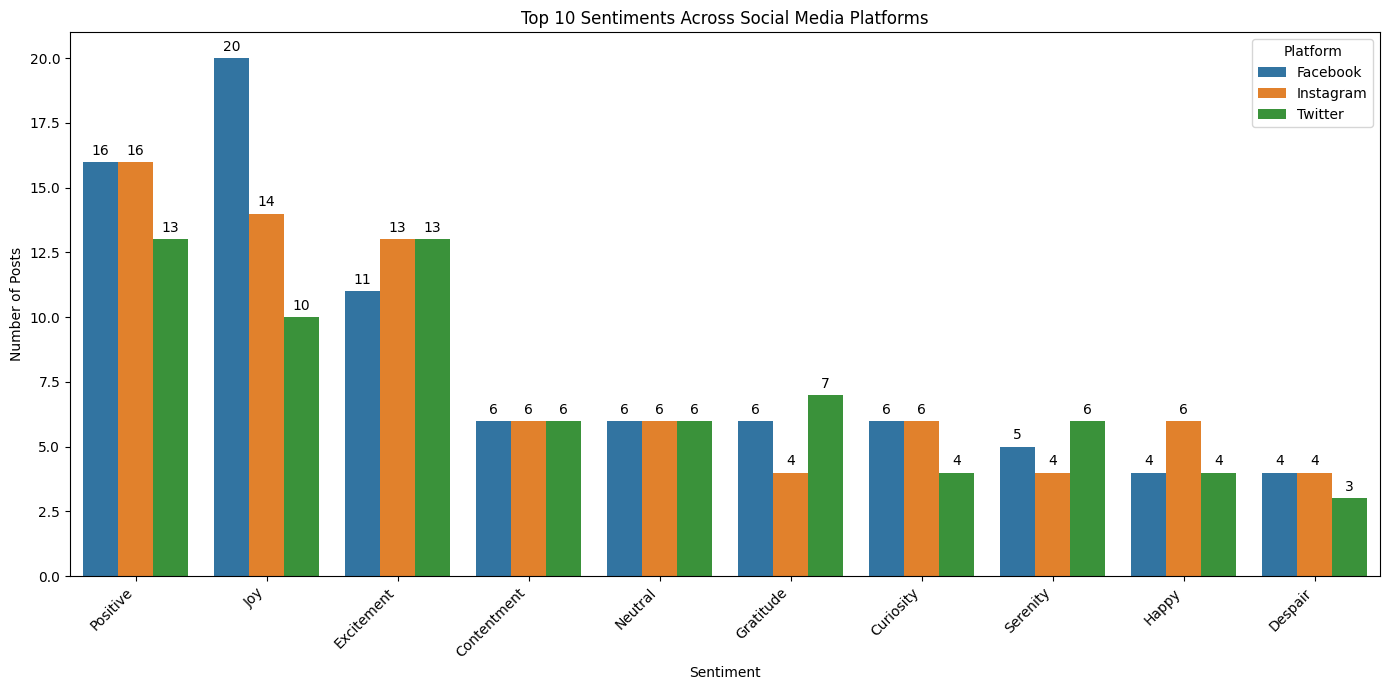

In [57]:
# Reset index
platform_sentiments_top10 = platform_sentiments_top10.reset_index()

# Reshape the DataFrame
platform_sentiments_melted = platform_sentiments_top10.melt(
    id_vars='Platform',
    var_name='Sentiment',
    value_name='Frequency'
)

# Plot grouped bar chart
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=platform_sentiments_melted,
    x='Sentiment',
    y='Frequency',
    hue='Platform'
)

# Add labels to all bars
for container in ax.containers:
    ax.bar_label(
        container,
        padding=3
    )

plt.title('Top 10 Sentiments Across Social Media Platforms')
plt.xlabel('Sentiment')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Platform')
plt.tight_layout()
plt.show()

### **Engagement per Platform Analysis**

**Observations:**

- Instagram leads in both post volume (252 posts) and total engagement (17,077). It also records the highest average engagement per post at 67.77.



- Twitter ranks second in total engagement (14,761), despite having fewer posts than Instagram.



- Facebook has the lowest post count (223) and total engagement (14,009). However, its average engagement (62.82) is slightly higher than Twitter's (62.55).

In [58]:
# calculate average engagement per platform
platform_engagement = data.groupby('Platform')['Total Engagement'].mean()

platform_engagement.sort_values(ascending=False).round(2)

,Total Engagement
Platform,
Instagram,67.77
Facebook,62.82
Twitter,62.55


In [59]:
# calculate post count and total engagement per platform
platform_summary = data.groupby('Platform').agg(
    Post_Count=('Total Engagement', 'count'),
    Total_Engagement=('Total Engagement', 'sum'),
    Average_Engagement=('Total Engagement', 'mean')
)

platform_summary.sort_values(
    by='Total_Engagement',
    ascending=False
)

,Post_Count,Total_Engagement,Average_Engagement
Platform,,,
Instagram,252,17077.0,67.765873
Twitter,236,14761.0,62.546610
Facebook,223,14009.0,62.820628


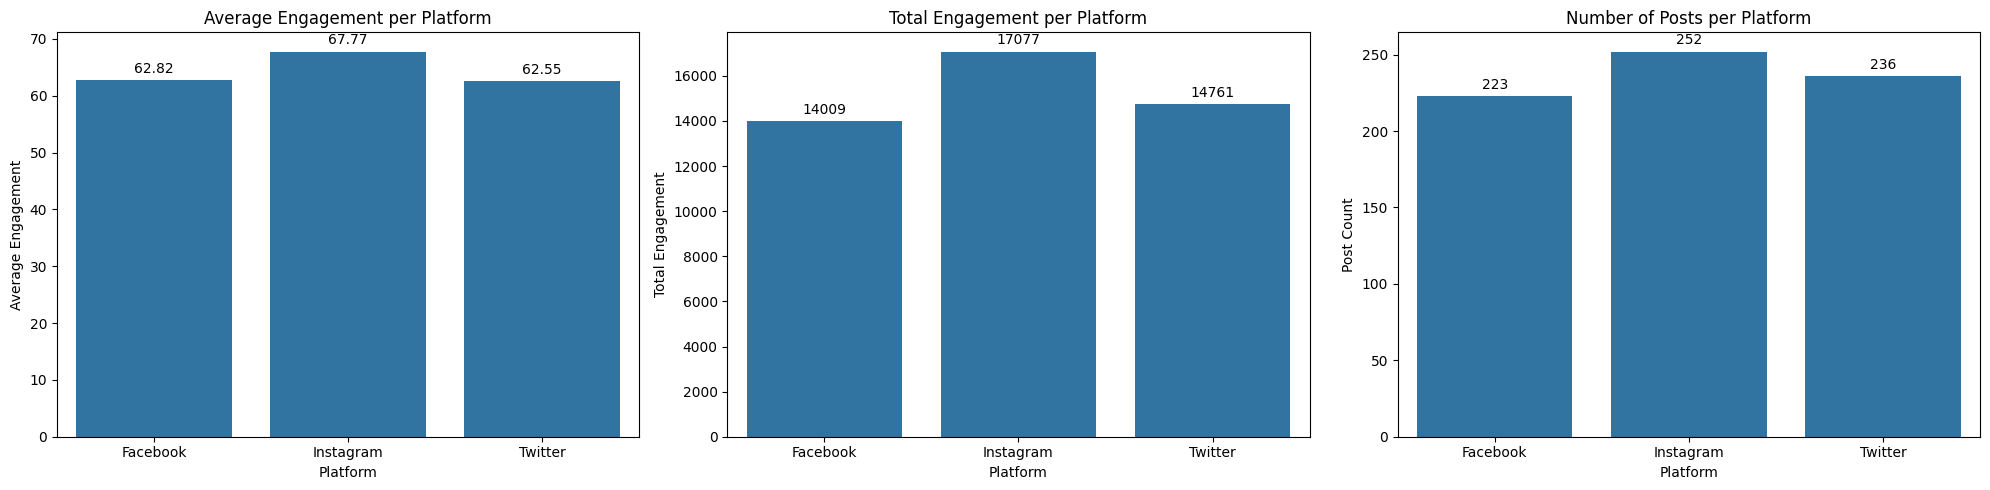

In [60]:
# Create subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Average Engagement
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Average_Engagement',
    ax=axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fmt='%.2f')

axes[0].set_title('Average Engagement per Platform')
axes[0].set_xlabel('Platform')
axes[0].set_ylabel('Average Engagement')


# 2. Total Engagement
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Total_Engagement',
    ax=axes[1]
)

for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fmt='%.0f')

axes[1].set_title('Total Engagement per Platform')
axes[1].set_xlabel('Platform')
axes[1].set_ylabel('Total Engagement')


# 3. Post Count
sns.barplot(
    data=platform_summary,
    x=platform_summary.index,
    y='Post_Count',
    ax=axes[2]
)

for container in axes[2].containers:
    axes[2].bar_label(container, padding=3, fmt='%.0f')

axes[2].set_title('Number of Posts per Platform')
axes[2].set_xlabel('Platform')
axes[2].set_ylabel('Post Count')


# Adjust layout
plt.tight_layout()
plt.show()

### **Engagement by Hour**


**Observations:**

- Highest average engagement: 11:00 PM records the highest average engagement at 85.00, across 7 posts, followed by 5:00 AM at 83.00, based on just 1 post.
- Lowest average engagement: 12:00 AM records the lowest average engagement at 53.00, based on 1 post.
- Daily fluctuations: Average engagement varies throughout the day, with generally higher values during the evening, particularly between 8:00 PM and 11:00 PM.
- Post volume vs. engagement: 2:00 PM has the highest post volume at 92 posts, but its average engagement is only 62.66. This suggests that a higher posting volume does not necessarily correspond to higher average engagement.

Note: Interpret averages from hours with very few posts cautiously, as they may not represent consistent engagement patterns.

In [61]:
# Calculate average engagement per hour
hourly_engagement = data.groupby('Hour').agg(
    Post_Count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# Sort by hour
hourly_engagement = hourly_engagement.sort_index()

# Round average engagement to 2 decimal places
hourly_engagement['Average_Engagement'] = hourly_engagement['Average_Engagement'].round(2)

# sort values
hourly_engagement.sort_values(by='Average_Engagement', ascending=False)

,Post_Count,Average_Engagement
Hour,,
23,7,85.00
5,1,83.00
22,33,75.88
20,49,75.45
13,29,68.76
18,63,67.30
19,74,67.09
21,40,66.42
7,6,64.67


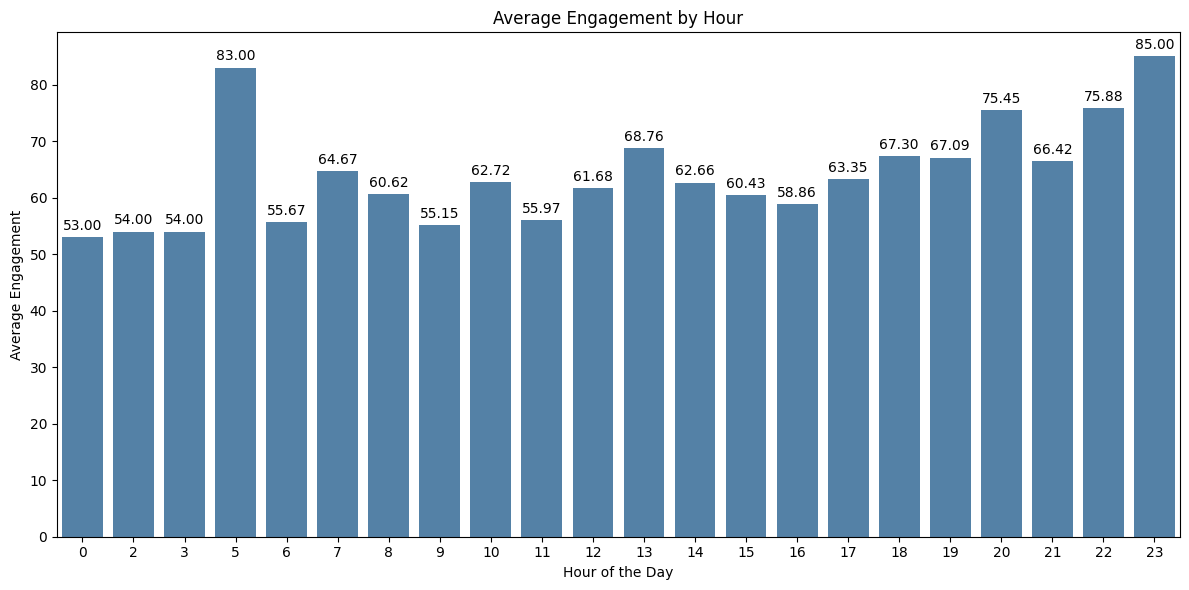

In [62]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=hourly_engagement.reset_index(),
    x='Hour',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()

### **Engagement by Day**

**Observations:**
- Highest average engagement: The 13th day records the highest average engagement at 79.00, across 7 posts, followed by the 4th day at 72.00 (5 posts) and the 2nd day at 71.89 (27 posts).
- Lowest average engagement: The 3rd day records the lowest average engagement at 54.80, across 20 posts.
- Engagement fluctuations: Average engagement varies throughout the month, with a noticeable decline from the 16th to the 19th, before increasing again on the 20th.
- Post volume vs. engagement: Higher post volume does not necessarily correspond to higher average engagement. For example, the 13th day has only 7 posts but the highest average engagement, while the 15th has the highest post volume at 71 posts, with an average engagement of 67.86.
- Additional insight: The 28th day also performs relatively well, recording an average engagement of 70.17 across 58 posts.

Note: Interpret averages from days with relatively few posts cautiously. Also, since the dataset covers multiple months or years, these results describe day-of-month patterns in the available data, not necessarily consistent performance on those calendar dates.

In [63]:
# calculate average engagement per day
daily_engagement = data.groupby('Day').agg(
    Post_count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# sort by day
daily_engagement = daily_engagement.sort_index()

# round average engagement to 2 decimal points
daily_engagement['Average_Engagement'] = daily_engagement['Average_Engagement'].round(2)

daily_engagement

,Post_count,Average_Engagement
Day,,
1,24,56.50
2,27,71.89
3,20,54.80
4,5,72.00
5,46,61.91
6,6,67.50
7,11,59.82
8,33,69.85
9,5,57.60


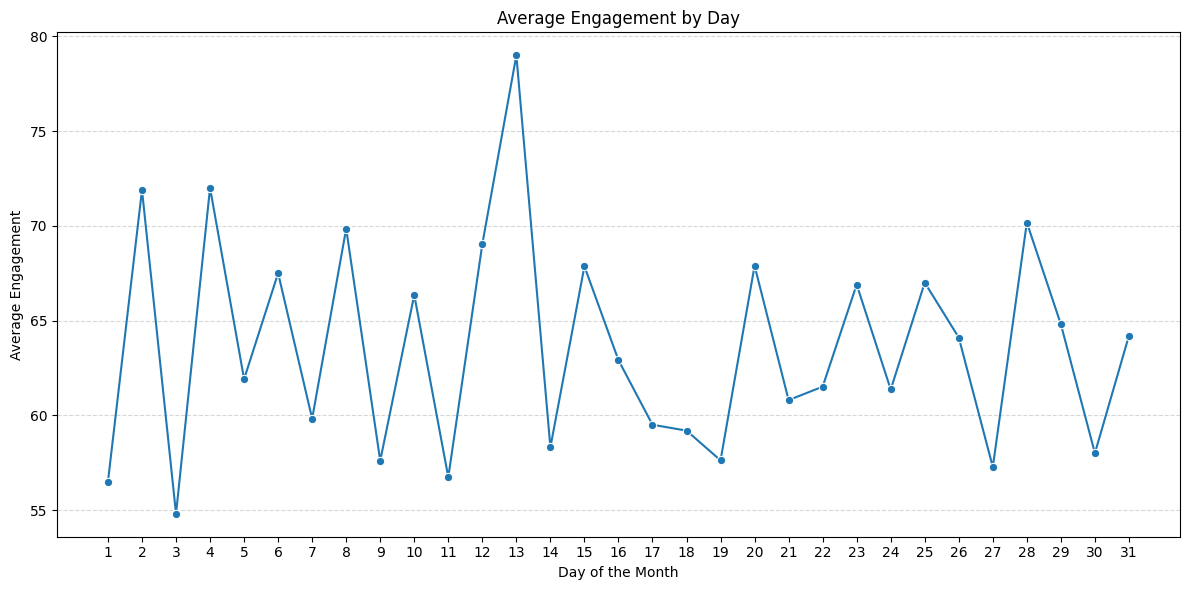

In [64]:
# plot line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_engagement.reset_index(),
    x='Day',
    y='Average_Engagement',
    marker='o'
)

plt.title('Average Engagement by Day')
plt.xlabel('Day of the Month')
plt.ylabel('Average Engagement')

plt.xticks(range(1, 32))
plt.grid(axis='y',
         linestyle='--',
         alpha=0.5
        )

plt.tight_layout()
plt.show()

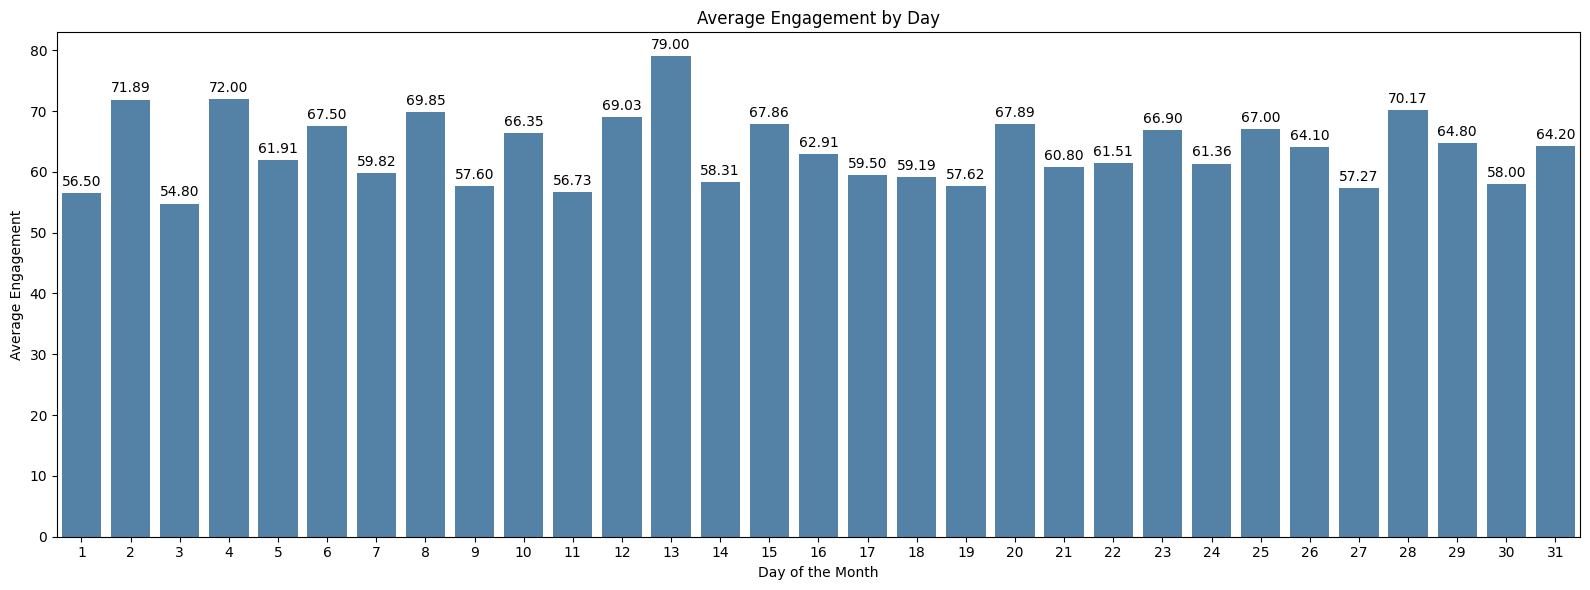

In [65]:
plt.figure(figsize=(16, 6))

ax = sns.barplot(
    data=daily_engagement.reset_index(),
    x='Day',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Day')
plt.xlabel('Day of the Month')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()

### **Engagement by Month**

**Observations:**

- Highest average engagement: July (Month 7) records the highest average engagement at 74.40, across 60 posts, followed by June at 71.07 (70 posts) and August at 65.91 (75 posts).



- Lowest average engagement: January (Month 1) records the lowest average engagement at 56.88, despite having 78 posts.



- Engagement fluctuations: Average engagement generally increases from January (56.88) through April (64.18), dips slightly in May (63.16), and rises to its peak in July (74.40). Engagement then declines in August and September.



- Post volume vs. engagement: Higher post volume does not necessarily correspond to higher average engagement. February has the highest post volume at 85 posts, but its average engagement is only 61.86, while July achieves the highest average with 60 posts.

In [66]:
# calculate average engagement per month
monthly_engagement = data.groupby('Month').agg(
    Post_Count=('Total Engagement', 'count'),
    Average_Engagement=('Total Engagement', 'mean')
)

# sort by month
monthly_engagement= monthly_engagement.sort_index()

# round average engagement to 2 decimal places
monthly_engagement['Average_Engagement'] = monthly_engagement['Average_Engagement'].round(2)

monthly_engagement

,Post_Count,Average_Engagement
Month,,
1,78,56.88
2,85,61.86
3,44,63.91
4,49,64.18
5,45,63.16
6,70,71.07
7,60,74.40
8,75,65.91
9,74,62.61


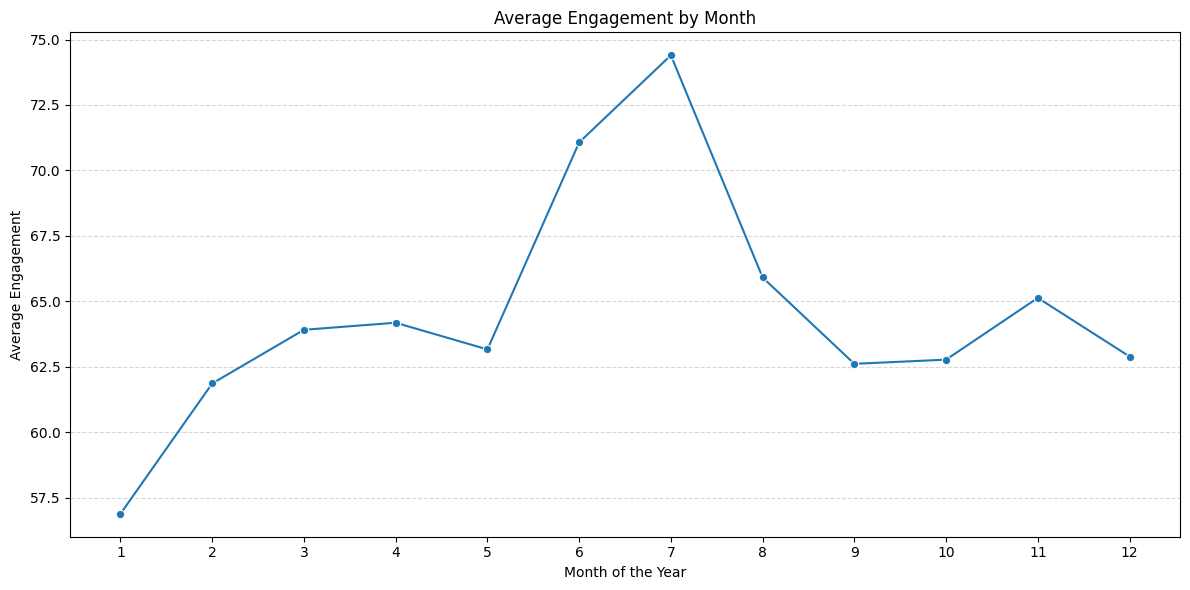

In [67]:
# plot line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_engagement.reset_index(),
    x='Month',
    y='Average_Engagement',
    marker='o'
)

plt.title('Average Engagement by Month')
plt.xlabel('Month of the Year')
plt.ylabel('Average Engagement')

plt.xticks(range(1, 13))
plt.grid(axis='y',
         linestyle='--',
         alpha=0.5
        )

plt.tight_layout()
plt.show()

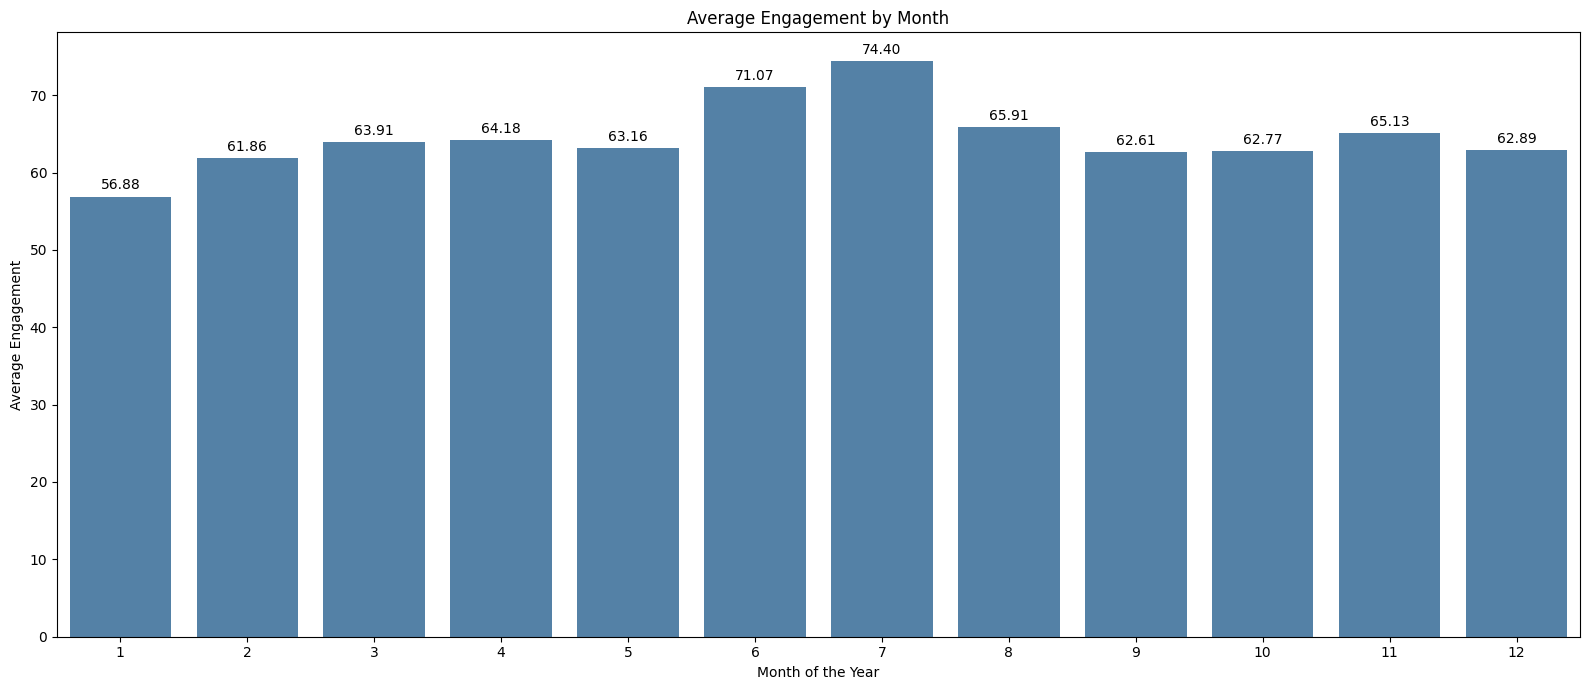

In [68]:
plt.figure(figsize=(16, 7))

ax = sns.barplot(
    data=monthly_engagement.reset_index(),
    x='Month',
    y='Average_Engagement',
    color='steelblue'
)

# add labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Month')
plt.xlabel('Month of the Year')
plt.ylabel('Average Engagement')

plt.tight_layout()
plt.show()

### **Correlation Analysis**

**Observations:**

- Likes and Retweets: Strong positive correlation of 0.9985.



- Likes and Total Engagement: Near-perfect positive correlation of 0.9998.



- Retweets and Total Engagement: Near-perfect positive correlation of 0.9993.



Overall insight: All three variables move closely together. However, the high correlations involving Total Engagement are expected because it is derived from Likes and Retweets.

In [70]:
engagement_corr = data[['Likes', 'Retweets', 'Total Engagement']]

correlation_matrix = engagement_corr.corr()

correlation_matrix

,Likes,Retweets,Total Engagement
Likes,1.000000,0.998476,0.999830
Retweets,0.998476,1.000000,0.999323
Total Engagement,0.999830,0.999323,1.000000


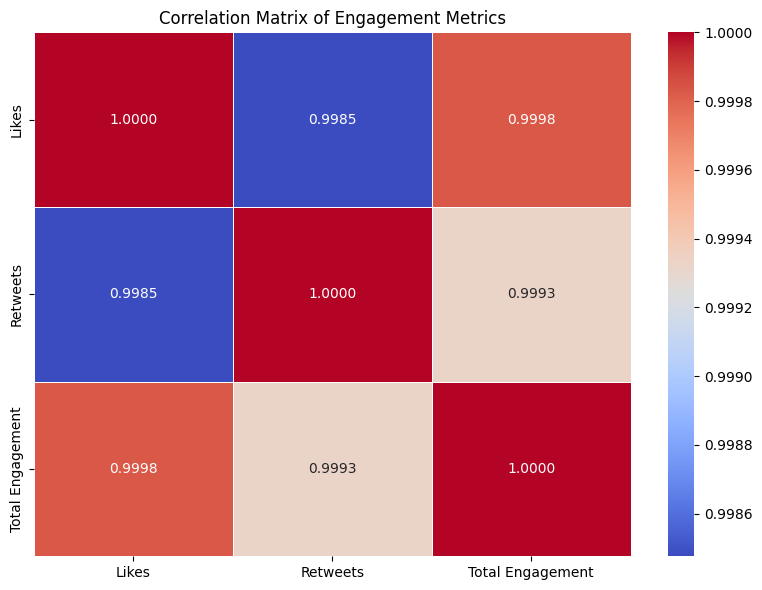

In [71]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    linewidth=0.5
)

plt.title('Correlation Matrix of Engagement Metrics')

plt.tight_layout()
plt.show()

### **Engagement by Sentiment**

**Observations:**
- Highest average engagement: Contentment leads with 78.11 across 18 posts, followed by Excitement (75.76) and Gratitude (74.12).



- Highest total engagement: Joy records the highest total engagement at 3,255 across 44 posts.



- Most frequent sentiment: Positive has the highest post count (45), but its average engagement is only 56.64.



- Lowest average engagement: Despair records the lowest average engagement among the selected categories at 53.55.



- Frequency vs. engagement: More frequent sentiments do not necessarily receive higher average engagement. For example, Contentment has 18 posts but a higher average engagement than Positive, which has 45.


In [72]:
sentiment_engagement = data.groupby('Sentiment').agg(
    Post_Count=('Total Engagement', 'count'),
    Total_Engagement=('Total Engagement', 'sum'),
    Average_Engagement=('Total Engagement', 'mean')
)

sentiment_engagement['Average_Engagement'] = sentiment_engagement['Average_Engagement'].round(2)

sentiment_engagement = sentiment_engagement.sort_values(
    by='Average_Engagement',
    ascending=False
)

sentiment_engagement

,Post_Count,Total_Engagement,Average_Engagement
Sentiment,,,
Motivation,1,120.0,120.00
Mesmerizing,1,120.0,120.00
Wonder,3,330.0,110.00
Ecstasy,1,105.0,105.00
Challenge,1,105.0,105.00
CulinaryOdyssey,1,105.0,105.00
Culinary Adventure,1,105.0,105.00
InnerJourney,1,105.0,105.00
Exhaustion,1,105.0,105.00


In [73]:
# get the top 10 most frequent sentiments
top_10_sentiments = data['Sentiment'].value_counts().head(10).index

# filter engagement data
top_sentiment_engagement = sentiment_engagement.loc[top_10_sentiments]

# sort by average engagement
top_sentiment_engagement = top_sentiment_engagement.sort_values(
    by='Average_Engagement',
    ascending=False
)

top_sentiment_engagement

,Post_Count,Total_Engagement,Average_Engagement
Sentiment,,,
Contentment,18,1406.0,78.11
Excitement,37,2803.0,75.76
Gratitude,17,1260.0,74.12
Joy,44,3255.0,73.98
Happy,14,955.0,68.21
Curiosity,16,1032.0,64.50
Serenity,15,953.0,63.53
Neutral,18,1099.0,61.06
Positive,45,2549.0,56.64


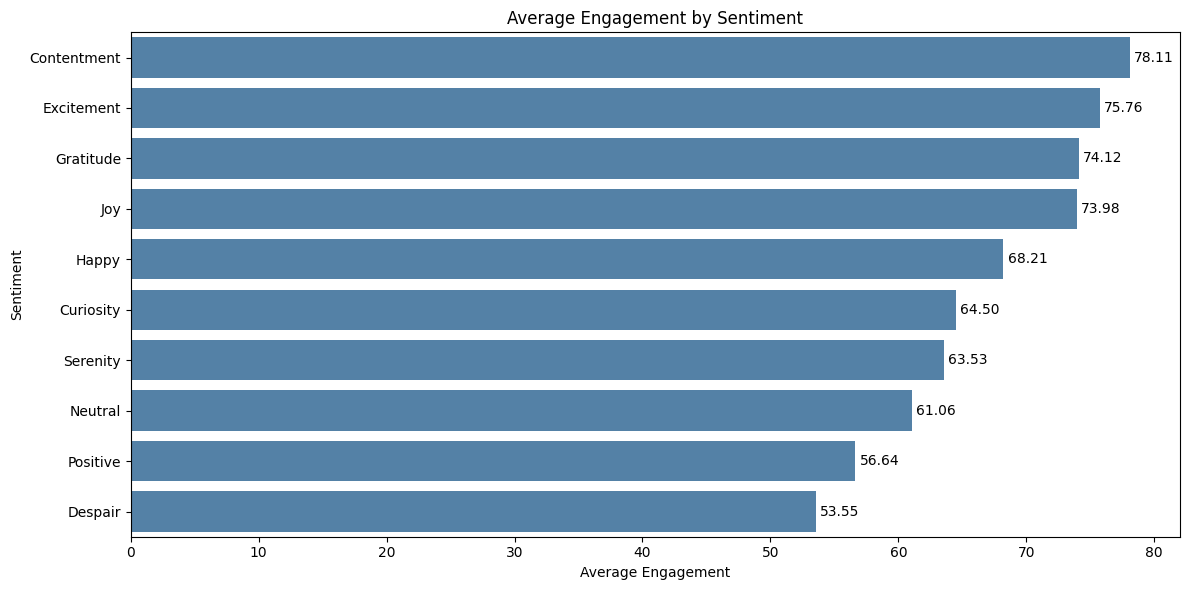

In [74]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_sentiment_engagement.reset_index(),
    x='Average_Engagement',
    y='Sentiment',
    color='steelblue'
)

for container in ax.containers:
  ax.bar_label(
      container,
      padding=3,
      fmt='%.2f'
  )

plt.title('Average Engagement by Sentiment')
plt.xlabel('Average Engagement')
plt.ylabel('Sentiment')

plt.tight_layout()
plt.show()

### **User Activity and Engagement Analysis**

**Observations:**

- User Distribution: The dataset contains 670 unique users across 711 posts.
- Posting Frequency: 631 users (94.18%) published only one post, while 37 users (5.52%) published two posts and 2 users (0.30%) published three posts.
- Most Active Users: NatureAdmirer and Bookworm are the most frequent contributors, with 3 posts each. Other repeat contributors published two posts each.
- Highest Average Engagement: The top 10 users by average engagement are tied at 120.00. Nine achieved this through a single post, while CosmosExplorer recorded the same average across two posts.
- Repeat User Engagement: Among repeat contributors, CosmosExplorer recorded the highest average engagement at 120.00, followed by MusicHarmonist and CulinaryExplorer at 105.00 each.

Overall Insight: User activity is widely distributed, with the vast majority of users contributing only one post. Although a small group of users published multiple posts, engagement varies considerably among repeat contributors. The limited posting frequency makes it difficult to establish consistent or long-term engagement performance.

In [75]:
unique_users = data['User'].nunique()

print(f'Total Unique Users: {unique_users} \n')

# get top 10 most active users
top_users = data['User'].value_counts().head(10)

top_users

Total Unique Users: 670 



,count
User,
NatureAdmirer,3
Bookworm,3
EchoedLaughter,2
PuzzleSolver,2
CulinaryExplorer,2
SunsetWatcher,2
CathedralVisitor,2
SpringEnthusiast,2
CosmosExplorer,2


In [81]:
# count the number of posts per user
user_post_frequency = data['User'].value_counts().value_counts().sort_index()

print(user_post_frequency, '\n')

# get percentage
user_post_frequency_percentage = (
    data['User'].value_counts()
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(user_post_frequency_percentage)

count
1    631
2     37
3      2
Name: count, dtype: int64 

count
1    94.18
2     5.52
3     0.30
Name: proportion, dtype: float64


In [82]:
# calculate engagement metrics per user
user_engagement = data.groupby('User').agg(
    Post_Count=('Total Engagement', 'count'),
    Total_Engagement=('Total Engagement', 'sum'),
    Average_Engagement=('Total Engagement', 'mean')
)

# sort users by average engagement
user_engagement = user_engagement.sort_values(
    by='Average_Engagement',
    ascending=False
)

user_engagement.head(10)

,Post_Count,Total_Engagement,Average_Engagement
User,,,
NatureEnthusiastSunsetWonder,1,120.0,120.0
MovieEnthusiastPremiereAttendee,1,120.0,120.0
BieberDanceEnthusiast,1,120.0,120.0
AdeleConcertGoer,1,120.0,120.0
DanceEnthusiastCityNightPerformance,1,120.0,120.0
CosmosExplorer,2,240.0,120.0
Wanderlust,1,120.0,120.0
SolitaryDescent,1,120.0,120.0
SunshineDancer,1,120.0,120.0


In [84]:
# Filter users who published exactly two posts
repeat_users = user_engagement[
    user_engagement['Post_Count'] > 1
]

# Sort by average engagement
repeat_users = repeat_users.sort_values(
    by='Average_Engagement',
    ascending=False
)

repeat_users

,Post_Count,Total_Engagement,Average_Engagement
User,,,
CosmosExplorer,2,240.0,120.000000
MusicHarmonist,2,210.0,105.000000
CulinaryExplorer,2,210.0,105.000000
EchoedLaughter,2,195.0,97.500000
GrowthSeeker,2,180.0,90.000000
DanceEnthusiast,2,166.0,83.000000
WinterWarmth,2,165.0,82.500000
Bookworm,3,247.0,82.333333
ForestDreamer,2,158.0,79.000000


### **Geographical Analysis**

### **Country Distribution**

- USA leads with 184 posts, followed by the UK (140) and Canada (132).
- Australia (70) and India (68) form the next group, with considerably fewer posts than the top three.
- There is a noticeable drop from India (68) to Brazil (17), suggesting that posting activity is heavily concentrated in the top five countries.
- The remaining countries in the top 10 each contribute fewer than 20 posts.


Overall insight: The dataset is geographically concentrated, with the USA, UK, and Canada accounting for approximately 64% of all recorded posts.

In [85]:
# count posts per country
country_distribution = data['Country'].value_counts()

country_distribution

,count
Country,
USA,184
UK,140
Canada,132
Australia,70
India,68
Brazil,17
France,16
Japan,15
Germany,14


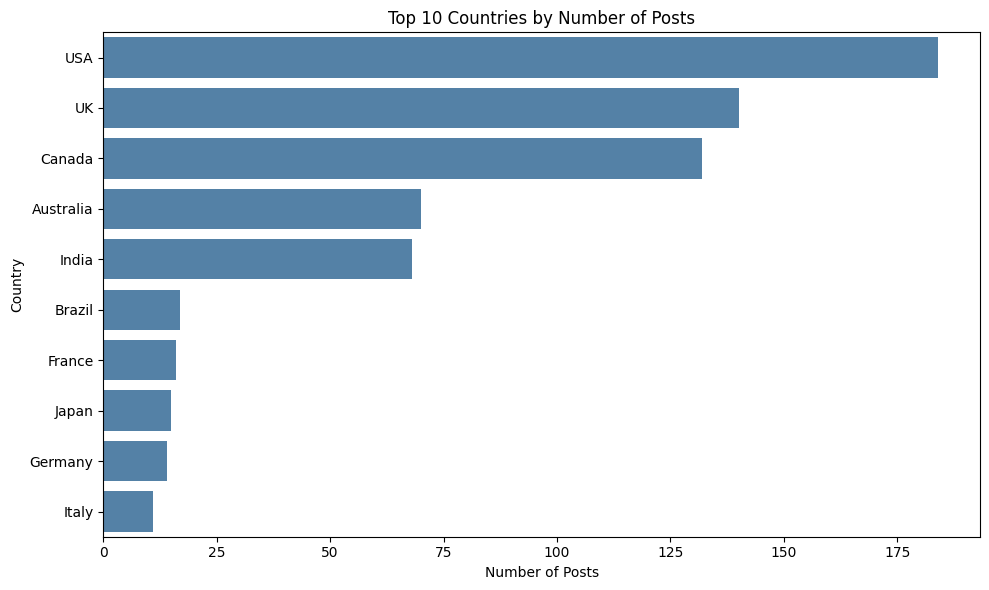

In [86]:
# get top 10 countries by post count
top_countries = data['Country'].value_counts().head(10)

# plot horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    color='steelblue'
)

plt.title('Top 10 Countries by Number of Posts')
plt.xlabel('Number of Posts')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### **Engagement by Country**

**Observations:**

- Brazil has the highest average engagement at 79.29 across 17 posts, followed closely by Japan at 78.53 across 15 posts.
- Germany ranks third with an average engagement of 72.43, followed by Italy (70.36) and France (69.50).
- USA leads in total engagement with 12,291 across 184 posts. Despite having the highest post volume, its average engagement is 66.80.
- UK and Canada generated 8,608 and 8,047 total engagements, respectively, but their average engagements are lower at 61.49 and 60.96.
- India has the lowest average engagement among the top 10 countries, at 57.50 across 68 posts.


Overall insight: Brazil and Japan have the highest average engagement despite contributing relatively few posts. Meanwhile, the USA dominates total engagement because of its substantially higher posting volume.

This highlights the difference between engagement volume and average engagement. Countries with fewer posts can still have higher engagement per post.

In [87]:
# Calculate engagement metrics per country
country_engagement = data.groupby('Country').agg(
    Post_Count=('Total Engagement', 'count'),
    Total_Engagement=('Total Engagement', 'sum'),
    Average_Engagement=('Total Engagement', 'mean')
)

# Get top 10 countries by post count
top_10_country_engagement = country_engagement.sort_values(
    by='Post_Count',
    ascending=False
).head(10)

# Sort by average engagement
top_10_country_engagement = top_10_country_engagement.sort_values(
    by='Average_Engagement',
    ascending=False
)

top_10_country_engagement.round(2)

,Post_Count,Total_Engagement,Average_Engagement
Country,,,
Brazil,17,1348.0,79.29
Japan,15,1178.0,78.53
Germany,14,1014.0,72.43
Italy,11,774.0,70.36
France,16,1112.0,69.50
USA,184,12291.0,66.80
UK,140,8608.0,61.49
Canada,132,8047.0,60.96
Australia,70,4084.0,58.34


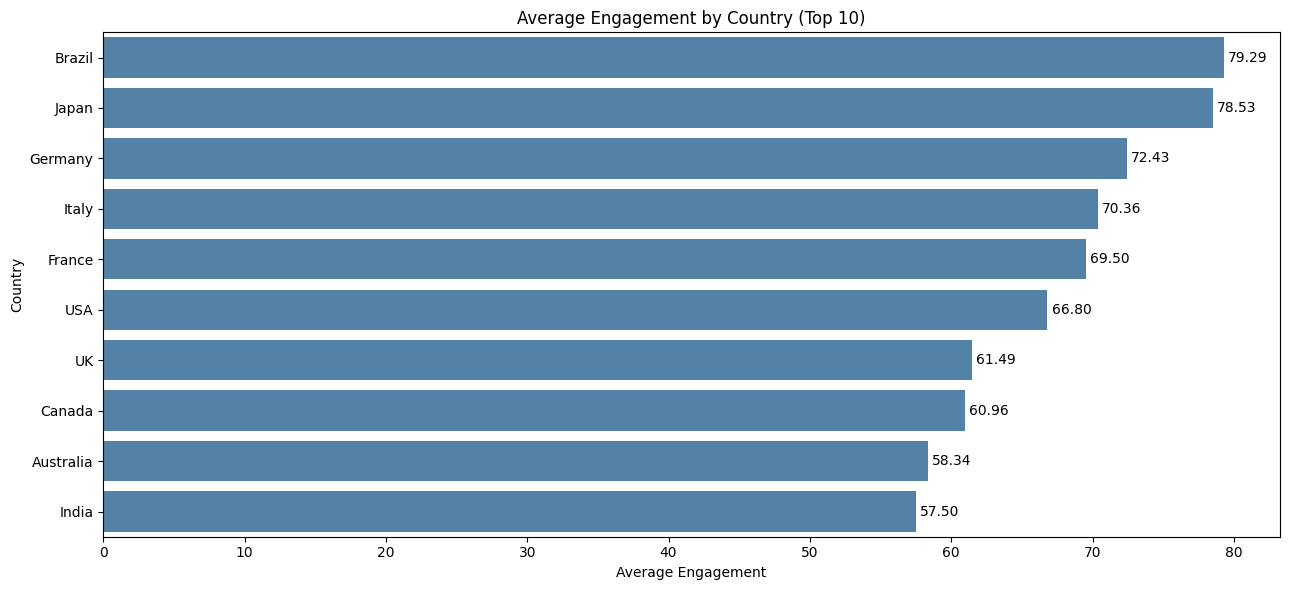

In [88]:
# Reset index to make Country a regular column
country_chart = top_10_country_engagement.reset_index()

# Create horizontal bar chart
plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=country_chart,
    x='Average_Engagement',
    y='Country',
    color='steelblue'
)

# Add data labels
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('Average Engagement by Country (Top 10)')
plt.xlabel('Average Engagement')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### **Platform by Country**

**Observations:**

- USA: Instagram leads with 71 posts, followed by Facebook (59) and Twitter (54).
- UK: Instagram is also the most frequently represented platform with 52 posts, followed by Twitter (47) and Facebook (41).
- Canada: Platform distribution is relatively balanced, with Twitter leading at 46 posts, while Facebook and Instagram both have 43.
- India: Twitter leads with 29 posts, compared with Facebook (20) and Instagram (19).
- Australia: Instagram leads with 26 posts, followed by Facebook (23) and Twitter (21).
- Smaller countries: Several countries have very few recorded posts, making platform comparisons less meaningful.


Overall insight: Instagram is the leading platform in the USA, UK, and Australia, while Twitter leads in Canada and India. However, platform preferences should be interpreted cautiously because this dataset only represents the recorded posts, not the entire social media population of each country.

In [89]:
# Get platform distribution by country
country_platform = pd.crosstab(
    data['Country'],
    data['Platform']
)

country_platform

Platform,Facebook,Instagram,Twitter
Country,,,
Australia,23,26,21
Austria,1,0,0
Belgium,0,0,2
Brazil,6,6,5
Cambodia,0,1,0
Canada,43,43,46
China,0,0,1
Colombia,1,0,0
Czech Republic,2,0,0


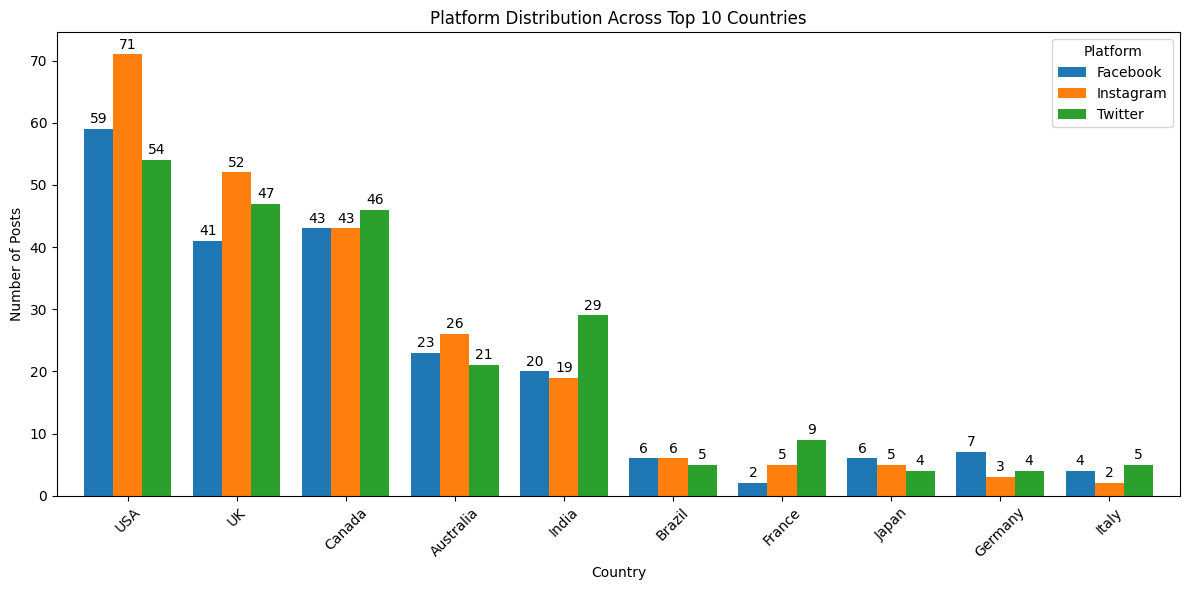

In [90]:
# Get top 10 countries by post count
top_10_countries = data['Country'].value_counts().head(10).index

# Filter platform distribution
top_10_country_platform = country_platform.loc[top_10_countries]

# Plot grouped bar chart
ax = top_10_country_platform.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

# bar labels
for container in ax.containers:
  ax.bar_label(
      container,
      padding=2,
      fmt='%d'
  )

plt.title('Platform Distribution Across Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.legend(title='Platform')
plt.tight_layout()
plt.show()

**Export Cleaned Dataset as CSV**
- The cleaned dataset used throughout the exploratory data analysis (EDA) will be exported as a CSV file for use in Power BI dashboard development.

In [128]:
# export
data.to_csv('social_media_cleaned.csv', index=False)

In [129]:
from google.colab import files

# download cleaned dataset
#files.download('social_media_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Conclusion**

The exploratory data analysis revealed several patterns in social media sentiment and engagement across platforms, time periods, users, and countries.

Instagram recorded the highest average engagement among the three platforms, while engagement levels varied across different hours, days, and months. July emerged as the month with the highest average engagement, while Contentment recorded the highest average engagement among the ten most frequently occurring sentiments.

The correlation analysis revealed extremely strong positive relationships among likes, retweets, and total engagement. However, this relationship is partly expected because total engagement is derived from the combination of likes and retweets.

User activity was highly dispersed, with 94.18% of users contributing only one post. Geographically, the USA, UK, and Canada accounted for the largest share of recorded posts, while Brazil and Japan demonstrated comparatively high average engagement despite their lower posting volumes.

Overall, the findings highlight the differences between engagement volume and average engagement, emphasizing the importance of examining multiple metrics rather than relying on post frequency alone.

The cleaned dataset and insights gathered from this analysis will serve as the foundation for the next phase of the project: developing an interactive Power BI dashboard to further explore and communicate social media engagement patterns.
